In [1]:
import arviz as az
import jax
import jax.numpy as jnp
import numpy as np
import numpyro
import numpyro.distributions as dist
from arviz_plots import plot_ecdf_pit
from numpyro.infer import MCMC, NUTS

import simuk

y = jnp.array([28, 8, -3, 7, -1, 1, 18, 12])
sigma = jnp.array([15, 10, 16, 11, 9, 11, 10, 18])


def noncentered_eight_schools(y=None):
    mu = numpyro.sample("mu", dist.Normal(0, 5))
    tau = numpyro.sample("tau", dist.HalfCauchy(5))

    theta_offset = numpyro.sample(
        "theta_offset",
        dist.Normal(0, 1).expand([8]),
    )

    theta = numpyro.deterministic(
        "theta",
        mu + tau * theta_offset,
    )

    numpyro.sample(
        "y",
        dist.Normal(theta, sigma),
        obs=y,
    )

In [2]:
rng_key = jax.random.PRNGKey(0)


def get_trace(model):
    nuts_kernel = NUTS(model)
    mcmc = MCMC(nuts_kernel, num_warmup=100, num_samples=1000)
    mcmc.run(rng_key=rng_key, y=y)
    trace = mcmc.get_samples(group_by_chain=True)
    return trace


trace_noncentered = get_trace(noncentered_eight_schools)

sample: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1100/1100 [00:00<00:00, 1206.89it/s, 7 steps of size 6.03e-01. acc. prob=0.78]


Need to reshape y to since schools aren't iid, to get a final shape of (1, 8)

In [3]:
reshaped_y = y.reshape(1, 8)

Construct an arviz object from the trace

In [4]:
dt = az.from_dict(
    {
        "posterior": trace_noncentered,
        "observed_data": {"y": reshaped_y},
    },
    dims={"mu": ["chain", "draw"], "y": ["observation_idx"]},
    coords={"y": np.arange(y.shape[0])},
    sample_dims=["chain", "draw"],
)

In [5]:
eight_schools_sbc = simuk.SBC(
    NUTS(noncentered_eight_schools),
    method="posterior",
    trace=dt,
    num_simulations=100,
    progress_bar=False,
    seed=1234,
    data_dir={"y": reshaped_y},
)

In [6]:
eight_schools_sbc.run_simulations()

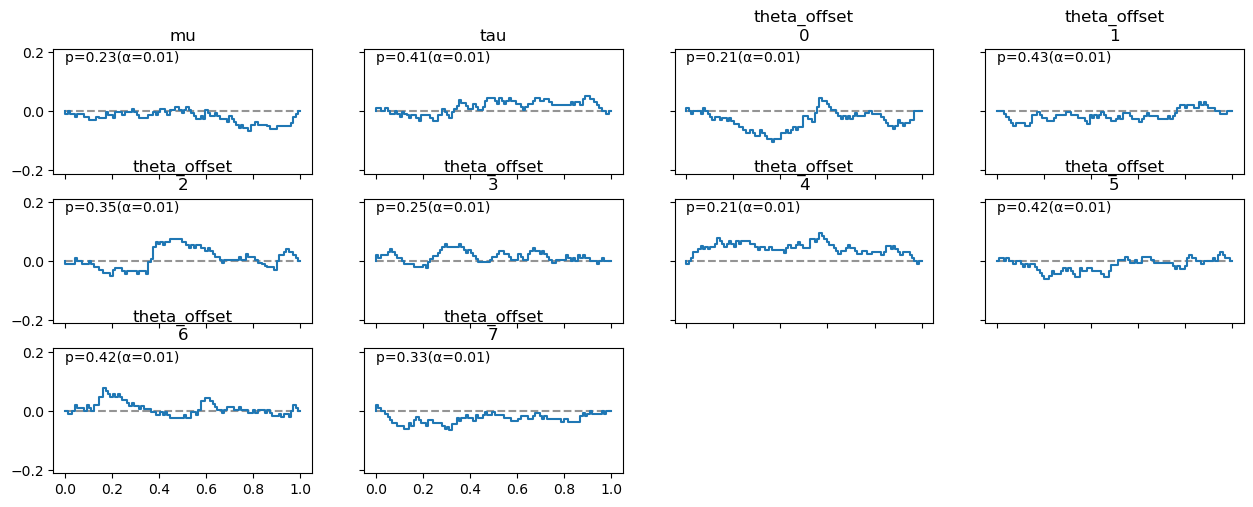

In [7]:
plot_ecdf_pit(
    eight_schools_sbc.simulations,
    group="posterior_sbc",
    visuals={"xlabel": False},
);

Using augment_observed to miscalibrate:

In [9]:
def augment_observed(model, observed_data, replicated_data, simulation_idx):
    data = {"y": np.array([2, 3, 5, 8, 1, 2, 3, 4])}
    return data


augmented_observed_sbc = simuk.SBC(
    NUTS(noncentered_eight_schools),
    method="posterior",
    trace=dt,
    num_simulations=100,
    progress_bar=False,
    seed=1234,
    augment_observed=augment_observed,
    data_dir={"y": reshaped_y},
)

In [10]:
augmented_observed_sbc.run_simulations()

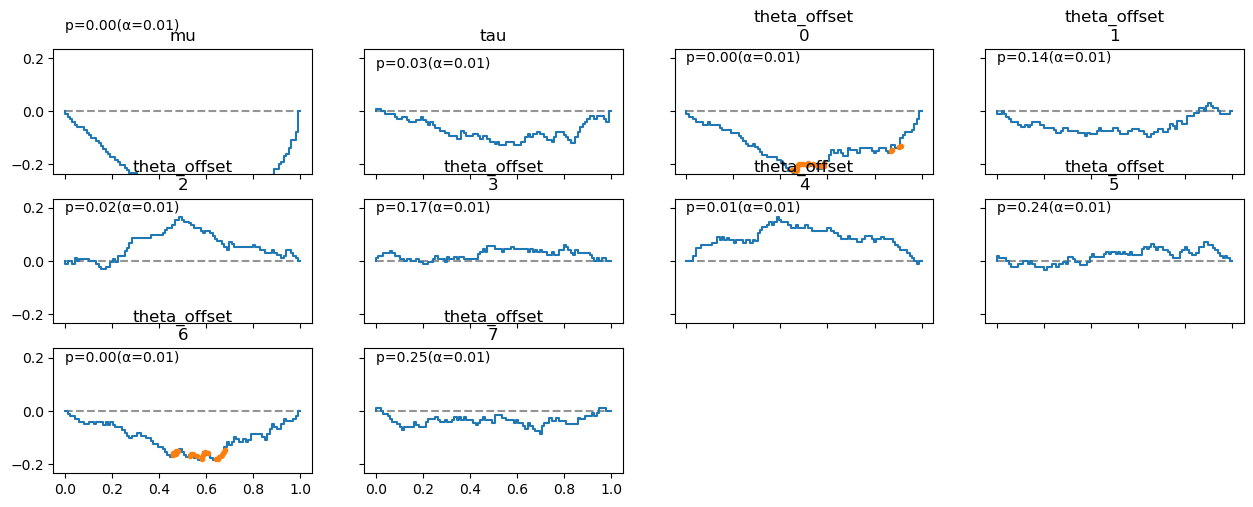

In [11]:
plot_ecdf_pit(
    augmented_observed_sbc.simulations,
    group="posterior_sbc",
    visuals={"xlabel": False},
);